# BBH Gravitational-Wave Detection Dataset — v2 (2-detector, whitened, PSD-calibrated)

Builds a large binary-classification dataset for **detecting binary-black-hole mergers in real LIGO noise**:

- `y = 0` — real LIGO noise (H1 + L1), possibly containing real glitches
- `y = 1` — the same kind of real noise with a simulated BBH signal injected into **both** detectors

Each example is a `(2, 4096)` array: H1 and L1, 2 s at 2048 Hz, **whitened** (noise ≈ unit variance, flat in 20–1000 Hz).

## What changed vs. the first notebook

| | v1 | v2 |
|---|---|---|
| Channels | 1 detector | **H1 + L1**, real antenna patterns (F+, F×) and the ±10 ms inter-site delay |
| Window | 1 s @ 4096 Hz | **2 s @ 2048 Hz**, merger placed randomly at 0.6–1.8 s (inspiral partly visible) |
| Conditioning | band-pass + divide by std | **Whitening** with a median-Welch PSD estimated per 64 s block |
| SNR | std-ratio heuristic | **True optimal (PSD-weighted) SNR** per detector and network; distance is *derived* from it |
| Waveforms | SEOBNRv4, non-spinning, plus polarisation only, 5–50 Msun | **IMRPhenomPv2 (precessing spins)**, 5–100 Msun each, h+ and h×, random inclination / phase / sky / polarisation |
| Noise | one file | **Many 4096 s epochs** across O3a/O3b with data-quality + hardware-injection + catalogued-event vetoes |
| Splits | random split of examples | **Split by epoch (time)**, so train/val/test never share noise; plus time-slides and real coincident data |
| Non-stationarity | none added | 4 **glitch families**, injected at the *same rate in both classes* (so they can't be a shortcut) |
| Evaluation sets | test | `val`, `test`, **`bench`** (fixed SNR bins, for efficiency-vs-SNR) and **`far`** (noise-only, for false-alarm rates) |
| Size | 10 k | **100 k (medium) – 400 k+ (large)**, written incrementally to chunked HDF5 |
| Metadata | 5 columns | **~50 columns**, plus the clean whitened signal `S` and a PSD table for the matched-filter baseline |

**How to use this notebook:** run everything down to *Step A* (about a minute, no downloads) to confirm the pipeline and the QC plots, then run *Step B* for the real dataset.

## 1. Installation

PyCBC pulls in LALSuite (large). On Colab this takes a few minutes the first time.

In [2]:
%pip install -q pycbc gwosc h5py scipy numpy pandas matplotlib tqdm requests

Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [3]:
import os, sys, json, time, math, warnings
import multiprocessing as mp
import numpy as np, pandas as pd, h5py
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import rfft, irfft, rfftfreq
from tqdm.auto import tqdm

/home/willowed/miniconda3/envs/gwml/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Configuration

Everything tunable lives in `CFG` / `PRESETS`. Key choices:

- **Presets** set the dataset size (`smoke` = pipeline test, `medium` = 100 k train, `large` = 400 k train).
  Call `set_preset(...)` first, then override individual entries if you want.
- **Mass prior:** detector-frame masses, `m1` from a mixture of a power law (−2.35) and a uniform distribution on [5, 100] Msun, `m2` uniform in [5, m1].
- **Spins:** magnitudes uniform up to 0.95; 50 % aligned, 50 % isotropic (precessing).
- **SNR:** train/val/test use a log-uniform optimal network SNR in [3, 40]; `bench` uses fixed values in `snr_bench`.
- **Glitches:** `p_glitch = 0.30` in *both* classes.

In [4]:
# ---------------- configuration ----------------
FS        = 2048            # Hz (4096 Hz GWOSC files are decimated by 2)
WINDOW_S  = 2.0             # length of each example fed to the network
PAD_S     = 1.0             # extra context each side, discarded after whitening
FRAME_S   = WINDOW_S + 2 * PAD_S      # 4 s == Welch segment length
N_WIN     = int(FS * WINDOW_S)        # 4096
N_FRAME   = int(FS * FRAME_S)         # 8192
N_PAD     = int(FS * PAD_S)
F_LOW, F_HIGH = 20.0, 1000.0          # analysis band [Hz]
F_LOWER_WF = 15.0                     # waveform start frequency (below F_LOW so the band edge is clean)
STRAIN_SCALE = 1e21                   # work in units of 1e-21 to keep floats O(1)
D_REF_MPC = 1000.0                    # bank waveforms are generated at this distance
BLOCK_S   = 64                        # PSD is estimated per 64 s block
BLOCK_N   = BLOCK_S * FS
HP_CUTOFF = 15.0                      # high-pass applied to raw strain
DETECTORS = ["H1", "L1"]
T_PEAK_RANGE = (0.6, 1.8)             # geocentric merger time inside the 2 s window [s]
BANK_PRE_S, BANK_POST_S = 3.0, 1.0    # stored waveform: 3 s before peak, 1 s after
BANK_PEAK = int(BANK_PRE_S * FS)
BANK_LEN  = int((BANK_PRE_S + BANK_POST_S) * FS)

APPROXIMANT = "IMRPhenomPv2"          # fast, precessing. Alternatives: "IMRPhenomD" (aligned, fastest), "IMRPhenomXPHM" (slow, higher modes)

CFG = dict(
    preset="smoke", seed=2026, synthetic_noise=False,
    out_dir="gw_bbh_dataset_v2", cache_dir="noise_cache", raw_dir="raw_noise",
    # priors
    m_min=5.0, m_max=100.0, p_mass_powerlaw=0.6, mass_alpha=-2.35,   # rest is uniform in [m_min, m_max]
    spin_max=0.95, p_aligned=0.5,
    # SNR sampling for train/val/test: log-uniform in [snr_min, snr_max]
    snr_min=3.0, snr_max=40.0,
    snr_bench=[4, 5, 6, 8, 10, 12, 15, 20, 30],
    # noise
    p_coincident=0.3,          # fraction of examples using real same-GPS H1/L1 data (rest are time slides)
    # glitches (same rate in BOTH classes so they are not a label shortcut)
    p_glitch=0.30, glitch_snr=(5.0, 60.0), p_glitch_both=0.2,
    save_clean_signal=("val", "test", "bench"),
    store_dtype="float32",
)

PRESETS = {
    #            train     val    test  bench/SNR   far-noise  reuse  epochs(train,val,test)
    "smoke":  dict(n_train=2_000,   n_val=400,    n_test=400,    n_bench=60,    n_far=1_000,   reuse=2, epochs=(1, 1, 1), epoch_s=1024),
    "medium": dict(n_train=100_000, n_val=10_000, n_test=10_000, n_bench=1_000, n_far=50_000,  reuse=4, epochs=(16, 3, 4), epoch_s=4096),
    "large":  dict(n_train=400_000, n_val=20_000, n_test=20_000, n_bench=2_000, n_far=200_000, reuse=5, epochs=(40, 5, 6), epoch_s=4096),
}

def set_preset(name):
    """Select a size preset. Call this BEFORE overriding individual CFG entries (e.g. CFG['n_train'])."""
    CFG["preset"] = name
    CFG.update(PRESETS[name])

set_preset("smoke")

## 4. Whitening and SNR

Raw strain spans many orders of magnitude in amplitude across frequency, so the network would otherwise spend its capacity learning the noise colour.
Each 4 s frame is tapered (Tukey, flat over the central 2 s), divided by the amplitude spectral density of its 64 s block, band-limited to 20–1000 Hz, and the central 2 s are kept.
Because whitening is linear, the *same* operator is applied to the waveform to get its exact optimal SNR:

`rho² = (2·BW/fs) · Σ y²`  for unit-variance whitened data.

This is the quantity that matched filtering would recover on average, so the dataset's "SNR" means the same thing as in a matched-filter search.

In [5]:
# ---------------- frequency-domain helpers ----------------
FREQS = rfftfreq(N_FRAME, 1.0 / FS)          # 4097 bins, df = 0.25 Hz
DF = FREQS[1] - FREQS[0]

def _band_mask(f=FREQS, lo=F_LOW, hi=F_HIGH, roll=3.0):
    """Smooth (raised-cosine) band-pass in the frequency domain."""
    m = np.zeros_like(f)
    m[(f >= lo) & (f <= hi)] = 1.0
    up = (f >= lo - roll) & (f < lo)
    m[up] = 0.5 * (1 - np.cos(np.pi * (f[up] - (lo - roll)) / roll))
    dn = (f > hi) & (f <= hi + roll)
    m[dn] = 0.5 * (1 + np.cos(np.pi * (f[dn] - hi) / roll))
    return m

BAND = _band_mask()
BW   = float(np.sum(BAND ** 2) * DF)          # effective bandwidth [Hz]
SNR2_FACTOR = 2.0 * BW / FS                   # rho^2 = SNR2_FACTOR * sum(y^2) for unit-variance whitened data
FRAME_TAPER = signal.windows.tukey(N_FRAME, alpha=2 * PAD_S / FRAME_S)   # flat over the central 2 s

def psd_to_whitener(psd):
    """One-sided PSD (units of 1e-21 strain)^2/Hz  ->  whitening filter with unit-variance output."""
    psd = np.asarray(psd, dtype=np.float64)
    G = np.zeros_like(psd)
    ok = (BAND > 0) & np.isfinite(psd) & (psd > 0)
    G[ok] = BAND[ok] / np.sqrt(psd[ok])
    return G / np.sqrt(BW)

def whiten_frames(frames, G):
    """frames (B,2,N_FRAME) raw, G (B,2,4097) -> whitened central windows (B,2,N_WIN)."""
    F = rfft(frames * FRAME_TAPER, axis=-1)
    y = irfft(F * G, n=N_FRAME, axis=-1)
    return y[..., N_PAD:N_PAD + N_WIN]

## 5. Real-noise preparation (GWOSC)

For each epoch and detector this: downloads the 4096 s / 4 kHz file, keeps seconds flagged `DATA` and `CBC_CAT1`, drops hardware-injection seconds and ±64 s around catalogued events,
decimates to 2048 Hz, high-passes at 15 Hz, estimates a PSD per 64 s block, and caches everything. `synthetic_noise=True` replaces the download with coloured Gaussian noise (for testing / Gaussian-noise ablations).

In [6]:
# ---------------- noise preparation ----------------
def estimate_block_psds(x, good_sec):
    """Median-averaged Welch PSD for every BLOCK_S block. x: float64 (n,), good_sec: bool per second.
    Returns (n_blocks, 4097) float32 with NaN for unusable blocks."""
    n_blocks = len(x) // BLOCK_N
    out = np.full((n_blocks, len(FREQS)), np.nan, dtype=np.float32)
    hop = N_FRAME // 2
    win = signal.windows.hann(N_FRAME)
    scale = 1.0 / (FS * np.sum(win ** 2))
    for b in range(n_blocks):
        b0 = b * BLOCK_N
        starts = np.arange(b0, b0 + BLOCK_N - N_FRAME + 1, hop)
        keep = [s for s in starts if good_sec[s // FS:(s + N_FRAME - 1) // FS + 1].all()]
        if len(keep) < 12:
            continue
        segs = np.stack([x[s:s + N_FRAME] for s in keep])
        segs = segs - segs.mean(axis=1, keepdims=True)
        P = np.abs(rfft(segs * win, axis=-1)) ** 2 * scale
        P[:, 1:-1] *= 2.0                                  # one-sided
        out[b] = (np.median(P, axis=0) / np.log(2.0)).astype(np.float32)   # median -> mean for chi^2_2
    return out

def valid_start_grid(good_sec, psd_blocks, n_samples, step=FS // 4):
    """Frame start indices whose 4 s frame is entirely good AND lies in a block with a valid PSD."""
    starts = np.arange(0, n_samples - N_FRAME, step)
    cum = np.concatenate([[0], np.cumsum(~good_sec)])
    a = starts // FS
    b = (starts + N_FRAME - 1) // FS + 1
    ok = (cum[b] - cum[a]) == 0
    blk = np.minimum((starts + N_FRAME // 2) // BLOCK_N, len(psd_blocks) - 1)
    ok &= np.isfinite(psd_blocks[blk, 100])
    return starts[ok]

def preprocess_strain(x, fs_in):
    """float64 strain -> scaled, decimated to FS, high-passed."""
    x = np.nan_to_num(np.asarray(x, dtype=np.float64)) * STRAIN_SCALE
    if int(fs_in) != FS:
        x = signal.resample_poly(x, FS, int(fs_in))
    sos = signal.butter(8, HP_CUTOFF, "highpass", fs=FS, output="sos")
    return signal.sosfiltfilt(sos, x)

def _save_epoch(ep_id, det, x, good_sec, gps0):
    good_sec = good_sec.copy(); good_sec[:4] = False; good_sec[-4:] = False      # filter transients at file edges
    psd = estimate_block_psds(x, good_sec)
    starts = valid_start_grid(good_sec, psd, len(x))
    base = os.path.join(CFG["cache_dir"], f"ep{ep_id:03d}_{det}")
    np.save(base + "_x.npy", x.astype(np.float32))
    np.save(base + "_psd.npy", psd)
    np.save(base + "_good.npy", good_sec)
    np.save(base + "_starts.npy", starts.astype(np.int64))
    json.dump(dict(gps0=float(gps0), n=len(x)), open(base + "_meta.json", "w"))
    return len(starts), int(np.isfinite(psd[:, 100]).sum()), len(psd)

# --- synthetic coloured Gaussian noise (smoke tests / Gaussian-noise ablation) ---
def make_synthetic_epoch(ep_id, rng, epoch_s):
    from pycbc.psd import aLIGOZeroDetHighPower
    n = int(epoch_s * FS)
    f = rfftfreq(n, 1 / FS)
    S = aLIGOZeroDetHighPower(len(f), f[1] - f[0], 10.0).numpy() * STRAIN_SCALE ** 2
    for det in DETECTORS:
        w = rng.standard_normal(n)
        x = irfft(rfft(w) * np.sqrt(S / (2.0 / FS)), n=n)
        # mild non-stationarity: slow amplitude drift + a few short loud bursts
        drift = 1 + 0.15 * np.sin(2 * np.pi * np.arange(n) / FS / rng.uniform(200, 900) + rng.uniform(0, 6))
        x = x * drift
        x = preprocess_strain(x / STRAIN_SCALE, FS)
        good = np.ones(n // FS, dtype=bool)
        gps0 = 1240000000 + ep_id * 5000
        print(f"  synthetic ep{ep_id} {det}:", _save_epoch(ep_id, det, x, good, gps0))

# --- real GWOSC data ---
def pick_epoch_times(n_epochs, seed, runs=None, min_len=4096 + 600):
    """Pick GPS times inside coincident H1+L1 CBC_CAT1 science segments, away from catalogued events."""
    from gwosc import timeline
    runs = runs or {"O3a": (1238166018, 1253977218), "O3b": (1256655618, 1269363618)}
    rng = np.random.default_rng(seed)
    segs = []
    for name, (a, b) in runs.items():
        per_det = []
        for det in DETECTORS:
            try:
                s = list(timeline.get_segments(f"{det}_CBC_CAT1", a, b))
            except Exception:
                s = list(timeline.get_segments(f"{det}_DATA", a, b))
            per_det.append(s)
        i = j = 0
        A, B = sorted(per_det[0]), sorted(per_det[1])
        while i < len(A) and j < len(B):                 # interval intersection
            lo, hi = max(A[i][0], B[j][0]), min(A[i][1], B[j][1])
            if hi - lo >= min_len:
                segs.append((lo, hi))
            if A[i][1] < B[j][1]: i += 1
            else: j += 1
    if not segs:
        raise RuntimeError("No coincident segments found - check your internet / gwosc version.")
    lens = np.array([hi - lo for lo, hi in segs], dtype=float)
    picks = []
    for _ in range(n_epochs):
        for _try in range(500):                                  # keep epochs >= 2 files apart
            lo, hi = segs[rng.choice(len(segs), p=lens / lens.sum())]
            t = int(lo + rng.uniform(0, hi - lo - 4096))
            if all(abs(t - p) > 8192 for p in picks):
                break
        picks.append(t)
    return picks

def event_times(start, stop):
    from gwosc import datasets
    out = []
    try:
        for ev in datasets.find_datasets(type="event", segment=(start, stop)):
            try: out.append(datasets.event_gps(ev))
            except Exception: pass
    except Exception as e:
        print("  (could not query event catalogue:", e, ")")
    return out

def download(url, path, retries=8, chunk=1 << 20):
    """Resumable download with retries; the file only appears at `path` once it is complete."""
    import requests, time
    if os.path.exists(path):
        return path
    part = path + ".part"
    for attempt in range(1, retries + 1):
        try:
            have = os.path.getsize(part) if os.path.exists(part) else 0
            headers = {"Range": f"bytes={have}-"} if have else {}
            with requests.get(url, stream=True, timeout=(30, 120), headers=headers) as r:
                if r.status_code == 416:                      # nothing left to fetch
                    total = have
                else:
                    r.raise_for_status()
                    if have and r.status_code != 206:         # server ignored Range: start over
                        have = 0
                    total = have + int(r.headers.get("Content-Length", 0))
                    with open(part, "ab" if have else "wb") as f:
                        for ch in r.iter_content(chunk):
                            f.write(ch)
            if total and os.path.getsize(part) != total:
                raise OSError(f"size mismatch: {os.path.getsize(part)} vs {total}")
            os.replace(part, path)
            return path
        except (requests.exceptions.RequestException, OSError) as e:
            print(f"    download interrupted ({type(e).__name__}); retry {attempt}/{retries}")
            time.sleep(min(60, 5 * attempt))
    raise RuntimeError(f"Could not download {url} after {retries} attempts - check your connection and re-run.")
def prepare_real_epoch(ep_id, t_gps, event_veto_s=64):
    from gwosc.locate import get_urls
    for det in DETECTORS:
        urls = get_urls(det, int(t_gps), int(t_gps) + 1, sample_rate=4096, format="hdf5")
        if not urls:
            raise RuntimeError(f"No file for {det} at {t_gps}")
        path = download(urls[0], os.path.join(CFG["raw_dir"], os.path.basename(urls[0])))
        with h5py.File(path, "r") as f:
            x = f["strain/Strain"][:]
            gps0 = float(f["meta/GPSstart"][()]); dur = int(f["meta/Duration"][()])
            fs_in = len(x) / dur
            good = np.isfinite(x.reshape(dur, -1)).all(axis=1)
            if "quality/simple/DQmask" in f:                      # require DATA + CBC_CAT1
                dq = f["quality/simple/DQmask"][:]
                names = [n.decode() if isinstance(n, bytes) else str(n) for n in f["quality/simple/DQShortnames"][()]]
                for need in ("DATA", "CBC_CAT1"):
                    if need in names:
                        good &= ((dq >> names.index(need)) & 1).astype(bool)[:dur]
            if "quality/injections/Injmask" in f:                # no hardware injections
                im = f["quality/injections/Injmask"][:]
                inames = [n.decode() if isinstance(n, bytes) else str(n) for n in f["quality/injections/InjShortnames"][()]]
                                # CW (fake-pulsar) injections run continuously, so NO_CW_HW_INJ is never set; ignore it.
                require = ("NO_CBC_HW_INJ", "NO_BURST_HW_INJ", "NO_DETCHAR_HW_INJ", "NO_STOCH_HW_INJ")
                for i, nm in enumerate(inames):
                    if nm in require:
                        good &= ((im >> i) & 1).astype(bool)[:dur]
        for et in event_times(gps0, gps0 + dur):                  # veto catalogued events
            lo = int(max(0, et - gps0 - event_veto_s)); hi = int(min(dur, et - gps0 + event_veto_s))
            good[lo:hi] = False
        # erode by 2 s so filter edge effects / gaps never leak into usable frames
        bad = ~good
        bad = signal.convolve(bad.astype(float), np.ones(5), mode="same") > 0
        good = ~bad
        xs = preprocess_strain(x, fs_in)
        print(f"  ep{ep_id} {det} GPS {gps0:.0f}  good={good.mean():.1%}  ->", _save_epoch(ep_id, det, xs, good, gps0))

## 6. Noise store

Draws a pair of 4 s frames (H1, L1). With probability `p_coincident` they are the real same-GPS data; otherwise they come from independent times (a **time slide**), which multiplies the number of distinct noise pairs while keeping each detector's real noise statistics.

In [7]:
# ---------------- noise store ----------------
class NoiseStore:
    """Memory-mapped access to prepared epochs; samples H1/L1 frames (coincident or time-slid)."""
    def __init__(self, epoch_ids):
        self.ids = list(epoch_ids)
        self.x, self.starts, self.psd, self.good, self.gps0, self.G = {}, {}, {}, {}, {}, {}
        for e in self.ids:
            for d in DETECTORS:
                base = os.path.join(CFG["cache_dir"], f"ep{e:03d}_{d}")
                self.x[e, d] = np.load(base + "_x.npy", mmap_mode="r")
                self.starts[e, d] = np.load(base + "_starts.npy")
                self.psd[e, d] = np.load(base + "_psd.npy")
                self.good[e, d] = np.load(base + "_good.npy")
                self.gps0[e, d] = json.load(open(base + "_meta.json"))["gps0"]
                self.G[e, d] = None
        self._cum = {k: np.concatenate([[0], np.cumsum(~v)]) for k, v in self.good.items()}

    def _whitener(self, e, d, blk):
        if self.G[e, d] is None:
            self.G[e, d] = {}
        c = self.G[e, d]
        if blk not in c:
            c[blk] = psd_to_whitener(self.psd[e, d][blk])
        return c[blk]

    def _blk(self, e, d, s):
        return int(min((s + N_FRAME // 2) // BLOCK_N, len(self.psd[e, d]) - 1))

    def _valid(self, e, d, s):
        n = len(self.x[e, d])
        if s < 0 or s + N_FRAME > n: return False
        c = self._cum[e, d]
        if c[(s + N_FRAME - 1) // FS + 1] - c[s // FS] != 0: return False
        return bool(np.isfinite(self.psd[e, d][self._blk(e, d, s)][100]))

    def draw(self, rng, p_coincident):
        eH = self.ids[rng.integers(len(self.ids))]
        sH = int(rng.choice(self.starts[eH, "H1"]))
        coincident = False
        if rng.random() < p_coincident:
            sL = int(round(sH + (self.gps0[eH, "H1"] - self.gps0[eH, "L1"]) * FS))
            if self._valid(eH, "L1", sL):
                eL, coincident = eH, True
        if not coincident:
            for _ in range(20):
                eL = self.ids[rng.integers(len(self.ids))]
                sL = int(rng.choice(self.starts[eL, "L1"]))
                if eL != eH or abs(sL - sH) > 20 * FS:
                    break
        frames = np.stack([np.asarray(self.x[eH, "H1"][sH:sH + N_FRAME], dtype=np.float64),
                           np.asarray(self.x[eL, "L1"][sL:sL + N_FRAME], dtype=np.float64)])
        bH, bL = self._blk(eH, "H1", sH), self._blk(eL, "L1", sL)
        G = np.stack([self._whitener(eH, "H1", bH), self._whitener(eL, "L1", bL)])
        gps_frame = self.gps0[eH, "H1"] + sH / FS
        meta = dict(epoch_H1=eH, epoch_L1=eL, start_H1=sH, start_L1=sL, blk_H1=bH, blk_L1=bL,
                    gps_H1=gps_frame, gps_L1=self.gps0[eL, "L1"] + sL / FS, coincident=coincident)
        return frames, G, meta

    def save_psd_table(self, path):
        with h5py.File(path, "w") as f:
            f.attrs["freqs_note"] = "one-sided PSD, units (1e-21 strain)^2/Hz, df=0.25 Hz, index with epoch/blk from metadata"
            for (e, d), p in self.psd.items():
                f.create_dataset(f"ep{e:03d}/{d}", data=p, compression="gzip")

## 7. Source priors and the waveform bank

Waveforms are generated once per bank entry (`h+`, `h×` at 1000 Mpc, with inclination and phase fixed) in parallel, then reused `reuse` times with different sky position, polarisation, arrival time, SNR and noise. Separate banks are drawn for train / val / test / bench.

In [8]:
# ---------------- source priors ----------------
def sample_intrinsic(rng, n):
    """Detector-frame BBH parameters. Returns a DataFrame with n rows."""
    c = CFG
    # masses: mixture of power-law (astrophysical-ish) and uniform (so heavy systems are well covered)
    m1 = np.where(rng.random(n) < c["p_mass_powerlaw"],
                  (rng.random(n) * (c["m_max"] ** (c["mass_alpha"] + 1) - c["m_min"] ** (c["mass_alpha"] + 1))
                   + c["m_min"] ** (c["mass_alpha"] + 1)) ** (1 / (c["mass_alpha"] + 1)),
                  rng.uniform(c["m_min"], c["m_max"], n))
    m2 = rng.uniform(c["m_min"], m1)
    # spins: magnitudes uniform, directions aligned (+-z) or isotropic
    a1, a2 = rng.uniform(0, c["spin_max"], n), rng.uniform(0, c["spin_max"], n)
    aligned = rng.random(n) < c["p_aligned"]
    def direction():
        ct = np.where(aligned, rng.choice([-1.0, 1.0], n), rng.uniform(-1, 1, n))
        ph = rng.uniform(0, 2 * np.pi, n)
        st = np.sqrt(1 - ct ** 2)
        return st * np.cos(ph), st * np.sin(ph), ct
    d1, d2 = direction(), direction()
    df = pd.DataFrame(dict(
        mass1=m1, mass2=m2,
        spin1x=a1 * d1[0], spin1y=a1 * d1[1], spin1z=a1 * d1[2],
        spin2x=a2 * d2[0], spin2y=a2 * d2[1], spin2z=a2 * d2[2],
        inclination=np.arccos(rng.uniform(-1, 1, n)),
        coa_phase=rng.uniform(0, 2 * np.pi, n),
        aligned_spins=aligned))
    M = m1 + m2; q = m2 / m1
    df["mtotal"] = M
    df["mchirp"] = (m1 * m2) ** 0.6 / M ** 0.2
    df["q"] = q
    df["chi_eff"] = (m1 * df.spin1z + m2 * df.spin2z) / M
    s1p, s2p = np.hypot(df.spin1x, df.spin1y), np.hypot(df.spin2x, df.spin2y)
    df["chi_p"] = np.maximum(s1p, (4 * q + 3) / (4 + 3 * q) * q * s2p)
    return df

def _bank_worker(p):
    try:
        from pycbc.waveform import get_td_waveform
        hp, hc = get_td_waveform(approximant=APPROXIMANT, delta_t=1.0 / FS, f_lower=F_LOWER_WF,
                                 distance=D_REF_MPC, **p)
        hp = hp.numpy() * STRAIN_SCALE; hc = hc.numpy() * STRAIN_SCALE
        ip = int(np.argmax(hp ** 2 + hc ** 2))
        out = np.zeros((2, BANK_LEN), dtype=np.float32)
        s0 = ip - BANK_PEAK
        a, b = max(0, s0), min(len(hp), s0 + BANK_LEN)
        out[0, a - s0:b - s0] = hp[a:b]; out[1, a - s0:b - s0] = hc[a:b]
        return out
    except Exception:
        return None

_WF_KEYS = ["mass1", "mass2", "spin1x", "spin1y", "spin1z", "spin2x", "spin2y", "spin2z", "inclination", "coa_phase"]

def make_bank(n, rng, n_proc=None, desc="bank"):
    """Generate n polarization pairs (hp,hc). Returns (params DataFrame, waveforms (n,2,BANK_LEN) float32)."""
    n_proc = n_proc or max(1, min(os.cpu_count() or 1, 8))
    df = sample_intrinsic(rng, int(n * 1.03) + 8)
    recs = [{k: float(r[k]) for k in _WF_KEYS} for _, r in df.iterrows()]
    if n_proc == 1:
        res = [_bank_worker(p) for p in tqdm(recs, desc=desc)]
    else:
        with mp.get_context("fork").Pool(n_proc) as pool:
            res = list(tqdm(pool.imap(_bank_worker, recs, chunksize=16), total=len(recs), desc=desc))
    ok = [i for i, r in enumerate(res) if r is not None][:n]
    if len(ok) < n:
        raise RuntimeError(f"Only {len(ok)}/{n} waveforms generated")
    wf = np.stack([res[i] for i in ok])
    return df.iloc[ok].reset_index(drop=True), wf

## 8. Glitches

Added in the whitened domain to one detector (80 %) or both (20 %), with an SNR of 5–60. Same probability for noise-only and signal examples.

In [9]:
# ---------------- glitches (added in the whitened domain, same prevalence in both classes) ----------------
GLITCH_TYPES = ["sine_gaussian", "blip", "chirping_whistle", "scattered_light"]

def make_glitch(rng, kind, snr):
    t = np.arange(N_WIN) / FS
    t0 = rng.uniform(0.25, 1.75)
    ph = rng.uniform(0, 2 * np.pi)
    if kind == "sine_gaussian":
        f0, Q = rng.uniform(30, 500), rng.uniform(4, 25); tau = Q / (2 * np.pi * f0)
        g = np.exp(-0.5 * ((t - t0) / tau) ** 2) * np.cos(2 * np.pi * f0 * (t - t0) + ph)
    elif kind == "blip":
        f0, Q = rng.uniform(60, 300), rng.uniform(1.5, 4); tau = Q / (2 * np.pi * f0)
        g = np.exp(-0.5 * ((t - t0) / tau) ** 2) * np.cos(2 * np.pi * f0 * (t - t0) + ph)
    elif kind == "chirping_whistle":
        f0, k, tau = rng.uniform(40, 200), rng.uniform(-400, 800), rng.uniform(0.03, 0.12)
        g = np.exp(-0.5 * ((t - t0) / tau) ** 2) * np.cos(2 * np.pi * (f0 * (t - t0) + 0.5 * k * (t - t0) ** 2) + ph)
    else:  # scattered_light: slow low-frequency arches
        f0, w = rng.uniform(20, 60), rng.uniform(0.3, 0.8)
        env = np.where(np.abs(t - t0) < w, 0.5 * (1 + np.cos(np.pi * (t - t0) / w)), 0.0)
        g = env * np.cos(2 * np.pi * f0 * (1 + 0.4 * np.sin(np.pi * (t - t0) / w)) * (t - t0) + ph)
    g = g * (snr / np.sqrt(SNR2_FACTOR * np.sum(g ** 2) + 1e-30))
    return g, t0, f0

## 9. Example builder

For every signal: sample sky/polarisation/arrival time → detector responses and delays (sub-sample, applied in the frequency domain) → whiten with the **actual PSD of the noise block it is injected into** → scale to the target network SNR → add to whitened noise.
Everything the network could be asked to predict is logged in the metadata.

In [10]:
# ---------------- example builder ----------------
_DET = {d: None for d in DETECTORS}
def _detector(d):
    if _DET[d] is None:
        from pycbc.detector import Detector
        _DET[d] = Detector(d)
    return _DET[d]

def make_chunk(labels, snrs, bank_ids, bank_wf, store, rng):
    B = len(labels)
    frames = np.empty((B, 2, N_FRAME)); G = np.empty((B, 2, len(FREQS)))
    metas = []
    for i in range(B):
        frames[i], G[i], m = store.draw(rng, CFG["p_coincident"])
        metas.append(m)
    X = whiten_frames(frames, G)                        # whitened noise (B,2,N_WIN)
    S = np.zeros_like(X)
    sig_rows = np.where(labels == 1)[0]
    ext = {}
    if len(sig_rows):
        ns = len(sig_rows)
        ra = rng.uniform(0, 2 * np.pi, ns); dec = np.arcsin(rng.uniform(-1, 1, ns)); psi = rng.uniform(0, np.pi, ns)
        u = rng.uniform(*T_PEAK_RANGE, ns)                       # geocentric peak time inside the window
        gps_pk = np.array([metas[i]["gps_H1"] for i in sig_rows]) + PAD_S + u
        Fp = np.zeros((ns, 2)); Fc = np.zeros((ns, 2)); tau = np.zeros((ns, 2))
        for k, d in enumerate(DETECTORS):
            det = _detector(d)
            Fp[:, k], Fc[:, k] = det.antenna_pattern(ra, dec, psi, gps_pk)
            tau[:, k] = det.time_delay_from_earth_center(ra, dec, gps_pk)
        wf = bank_wf[bank_ids[sig_rows]]                         # (ns,2,BANK_LEN): hp,hc
        t_pk = (PAD_S + u) * FS
        n0 = np.floor(t_pk).astype(int); frac = t_pk - n0
        h = np.zeros((ns, 2, N_FRAME))
        for j in range(ns):
            s0 = n0[j] - BANK_PEAK
            a, b = max(0, s0), min(N_FRAME, s0 + BANK_LEN)
            for k in range(2):
                h[j, k, a:b] = (Fp[j, k] * wf[j, 0] + Fc[j, k] * wf[j, 1])[a - s0:b - s0]
        shift = frac[:, None] / FS + tau                          # seconds, per detector
        H = rfft(h, axis=-1) * np.exp(-2j * np.pi * FREQS[None, None, :] * shift[..., None])
        h = irfft(H, n=N_FRAME, axis=-1)
        Yh = whiten_frames(h, G[sig_rows])                        # unit-noise whitening of the signal
        rho2_det = SNR2_FACTOR * np.sum(Yh ** 2, axis=-1)         # optimal SNR^2 per detector at D_REF
        rho_ref = np.sqrt(rho2_det.sum(axis=1))
        scale = snrs[sig_rows] / rho_ref
        Yh *= scale[:, None, None]
        S[sig_rows] = Yh; X[sig_rows] += Yh
        ext = dict(ra=ra, dec=dec, psi=psi, t_peak_s=u, Fp_H1=Fp[:, 0], Fc_H1=Fc[:, 0], Fp_L1=Fp[:, 1], Fc_L1=Fc[:, 1],
                   dt_L1_H1_ms=1e3 * (tau[:, 1] - tau[:, 0]), distance_mpc=D_REF_MPC / scale,
                   snr_H1=np.sqrt(rho2_det[:, 0]) * scale, snr_L1=np.sqrt(rho2_det[:, 1]) * scale, snr_net=snrs[sig_rows])
    # glitches
    gl = [dict(glitch_det="", glitch_type="", glitch_snr=np.nan, glitch_t0=np.nan, glitch_f0=np.nan) for _ in range(B)]
    for i in range(B):
        if rng.random() < CFG["p_glitch"]:
            dets = [0, 1] if rng.random() < CFG["p_glitch_both"] else [int(rng.integers(2))]
            best = None
            for k in dets:
                kind = GLITCH_TYPES[rng.integers(len(GLITCH_TYPES))]
                gsnr = float(np.exp(rng.uniform(np.log(CFG["glitch_snr"][0]), np.log(CFG["glitch_snr"][1]))))
                g, t0, f0 = make_glitch(rng, kind, gsnr)
                X[i, k] += g
                if best is None or gsnr > best[2]:
                    best = (kind, k, gsnr, t0, f0)
            gl[i] = dict(glitch_det="both" if len(dets) == 2 else DETECTORS[best[1]], glitch_type=best[0],
                         glitch_snr=best[2], glitch_t0=best[3], glitch_f0=best[4])
    # per-example noise-quality statistics of the final window
    std = X.std(axis=-1)
    mad = 1.4826 * np.median(np.abs(X - np.median(X, axis=-1, keepdims=True)), axis=-1)
    rows = []
    for i in range(B):
        r = dict(metas[i]); r.update(gl[i])
        r.update(std_H1=std[i, 0], std_L1=std[i, 1], robust_std_H1=mad[i, 0], robust_std_L1=mad[i, 1])
        rows.append(r)
    sig_df = pd.DataFrame(ext, index=sig_rows) if len(sig_rows) else pd.DataFrame()
    return X.astype(CFG["store_dtype"]), S.astype(CFG["store_dtype"]), pd.DataFrame(rows), sig_df, sig_rows

def build_split(name, n_sig, n_noise, snr_fn, epoch_ids, rng, bank_df, bank_wf, chunk=500):
    """Build one split and write <out_dir>/<name>.h5 and <name>_meta.csv."""
    n = n_sig + n_noise
    labels = np.array([1] * n_sig + [0] * n_noise, dtype=np.int8)
    rng.shuffle(labels)
    snrs = np.zeros(n); snrs[labels == 1] = snr_fn(n_sig)
    reuse = int(np.ceil(n_sig / max(1, len(bank_df))))
    pool = np.tile(np.arange(len(bank_df)), reuse); rng.shuffle(pool)
    bank_ids = np.full(n, -1); bank_ids[labels == 1] = pool[:n_sig]
    store = NoiseStore(epoch_ids)
    keep_S = any(name.startswith(k) for k in CFG["save_clean_signal"])
    path = os.path.join(CFG["out_dir"], f"{name}.h5")
    all_meta = []
    with h5py.File(path, "w") as f:
        dX = f.create_dataset("X", (n, 2, N_WIN), dtype=CFG["store_dtype"], chunks=(min(256, n), 2, N_WIN))
        dy = f.create_dataset("y", data=labels)
        dS = f.create_dataset("S", (n, 2, N_WIN), dtype=CFG["store_dtype"], chunks=(min(256, n), 2, N_WIN)) if keep_S else None
        for a in tqdm(range(0, n, chunk), desc=f"{name}"):
            b = min(n, a + chunk)
            X, S, base, sig_df, sig_rows = make_chunk(labels[a:b], snrs[a:b], bank_ids[a:b], bank_wf, store, rng)
            dX[a:b] = X
            if dS is not None: dS[a:b] = S
            m = base.copy()
            m.insert(0, "idx", np.arange(a, b)); m.insert(1, "label", labels[a:b]); m.insert(2, "bank_id", bank_ids[a:b])
            if len(sig_df):
                for col in sig_df.columns:
                    m.loc[sig_rows, col] = sig_df[col].values
                bp = bank_df.iloc[bank_ids[a:b][sig_rows]].reset_index(drop=True)
                for col in bp.columns:
                    m.loc[sig_rows, col] = bp[col].values
            all_meta.append(m)
        f.attrs.update(dict(fs=FS, window_s=WINDOW_S, band=[F_LOW, F_HIGH], channels="H1,L1", approximant=APPROXIMANT,
                            whitening="per-64s-block median-Welch PSD, unit-variance", split=name, preset=CFG["preset"]))
    meta = pd.concat(all_meta, ignore_index=True)
    meta.insert(0, "split", name)
    meta.to_csv(os.path.join(CFG["out_dir"], f"{name}_meta.csv"), index=False)
    print(f"  {name}: X{(n, 2, N_WIN)}  signals={int(labels.sum())}  noise={int((labels == 0).sum())}  -> {path}")
    return meta

## 10. Driver

Splits: `train`, `val`, `test` (balanced), `bench` (signals at fixed SNRs), `far` (noise only). `val/test/bench` also store the clean whitened signal `S`.

In [11]:
# ---------------- driver ----------------
def prepare_epochs(rng):
    n_tr, n_va, n_te = CFG["epochs"]
    total = n_tr + n_va + n_te
    todo = [e for e in range(total) if not all(os.path.exists(os.path.join(CFG["cache_dir"], f"ep{e:03d}_{d}_x.npy")) for d in DETECTORS)]
    if not todo:
        print("All noise epochs already cached."); return
    if CFG["synthetic_noise"]:
        for e in todo: make_synthetic_epoch(e, rng, CFG["epoch_s"])
    else:
        times = pick_epoch_times(total, CFG["seed"])
        for e in todo:
            print(f"epoch {e}: GPS ~{times[e]}")
            prepare_real_epoch(e, times[e])

def build_all():
    for d in (CFG["out_dir"], CFG["cache_dir"], CFG["raw_dir"]):
        os.makedirs(d, exist_ok=True)
    rng = np.random.default_rng(CFG["seed"])
    prepare_epochs(rng)
    n_tr, n_va, n_te = CFG["epochs"]
    ep = dict(train=list(range(n_tr)), val=list(range(n_tr, n_tr + n_va)), test=list(range(n_tr + n_va, n_tr + n_va + n_te)))
    ep["bench"] = ep["far"] = ep["test"]
    snr = lambda n: np.exp(rng.uniform(np.log(CFG["snr_min"]), np.log(CFG["snr_max"]), n))
    metas = {}
    plan = [("train", CFG["n_train"] // 2, CFG["n_train"] - CFG["n_train"] // 2, snr),
            ("val",   CFG["n_val"] // 2,   CFG["n_val"] - CFG["n_val"] // 2,   snr),
            ("test",  CFG["n_test"] // 2,  CFG["n_test"] - CFG["n_test"] // 2, snr)]
    for name, ns, nn, fn in plan:
        t = time.time()
        bdf, bwf = make_bank(max(50, int(np.ceil(ns / CFG["reuse"]))), rng, desc=f"{name} waveform bank")
        metas[name] = build_split(name, ns, nn, fn, ep[name], rng, bdf, bwf)
        del bwf
    # SNR benchmark: fixed optimal network SNR per bin, signals only (use 'far' noise for negatives)
    bsnr = np.repeat(CFG["snr_bench"], CFG["n_bench"]).astype(float)
    bdf, bwf = make_bank(max(50, CFG["n_bench"]), rng, desc="bench waveform bank")
    metas["bench"] = build_split("bench", len(bsnr), 0, lambda n: rng.permutation(bsnr), ep["bench"], rng, bdf, bwf)
    del bwf
    metas["far"] = build_split("far", 0, CFG["n_far"], lambda n: np.zeros(0), ep["far"], rng,
                               pd.DataFrame(columns=_WF_KEYS), np.zeros((1, 2, BANK_LEN), np.float32))
    NoiseStore(sum([ep["train"], ep["val"], ep["test"]], [])).save_psd_table(os.path.join(CFG["out_dir"], "psd_table.h5"))
    json.dump(dict(cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()},
                   fs=FS, window_s=WINDOW_S, band=[F_LOW, F_HIGH], approximant=APPROXIMANT,
                   epochs={k: v for k, v in ep.items()}),
              open(os.path.join(CFG["out_dir"], "dataset_card.json"), "w"), indent=2, default=str)
    return metas

## 11. Quality-control helpers

In [12]:
# ---------------- QC: load + plots ----------------
def load_split(name, out_dir=None, with_signal=False, n=None):
    out_dir = out_dir or CFG["out_dir"]
    with h5py.File(os.path.join(out_dir, f"{name}.h5"), "r") as f:
        X = f["X"][:n]; y = f["y"][:n]
        S = f["S"][:n] if (with_signal and "S" in f) else None
    meta = pd.read_csv(os.path.join(out_dir, f"{name}_meta.csv"), nrows=n)
    return X, y, meta, S

def qc_noise_whitening(out_dir=None):
    """Whitened noise-only data should have unit variance and a flat PSD inside the band."""
    X, y, m, _ = load_split("far", out_dir, n=5000)
    clean = m.glitch_type.isna().values
    fr, P = signal.welch(X[clean].astype(np.float64), fs=FS, nperseg=1024, axis=-1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for k, d in enumerate(DETECTORS):
        ax[0].semilogy(fr, P[:, k].mean(0), label=d)
    ax[0].axvspan(F_LOW, F_HIGH, color="g", alpha=.08); ax[0].axhline(2 / FS, color="k", ls=":", label="ideal flat level")
    ax[0].set(xlabel="Hz", ylabel="PSD of whitened noise", title="Whitened noise PSD (flat in band = good)"); ax[0].legend()
    ax[1].hist(m.robust_std_H1[clean], 60, alpha=.6, label="H1"); ax[1].hist(m.robust_std_L1[clean], 60, alpha=.6, label="L1")
    ax[1].set(xlabel="robust std of whitened window", title="Noise non-stationarity (1.0 = PSD matches)"); ax[1].legend()
    plt.tight_layout(); plt.show()
    print("mean std of clean noise windows (should be ~1):", X[clean].std(axis=-1).mean(0))

def qc_examples(split="val", snr_target=20, out_dir=None):
    X, y, m, S = load_split(split, out_dir, with_signal=True)
    i_sig = int(np.argmin(np.where(y == 1, np.abs(m.snr_net.fillna(-99) - snr_target), 1e9)))
    i_noi = int(np.where(y == 0)[0][0])
    t = np.arange(N_WIN) / FS
    fig, ax = plt.subplots(2, 3, figsize=(16, 6))
    for r, (i, ttl) in enumerate([(i_sig, f"signal, net SNR {m.snr_net[i_sig]:.1f}, M=({m.mass1[i_sig]:.0f},{m.mass2[i_sig]:.0f}), d={m.distance_mpc[i_sig]:.0f} Mpc"),
                                  (i_noi, "noise only")]):
        for k, d in enumerate(DETECTORS):
            ax[r, 0].plot(t, X[i, k] + 8 * (1 - k), lw=.6, label=d)
            if S is not None and y[i] == 1: ax[r, 0].plot(t, S[i, k] + 8 * (1 - k), "k", lw=.8, alpha=.7)
        ax[r, 0].set(title=ttl, xlabel="s"); ax[r, 0].legend(loc="upper left")
        for k, d in enumerate(DETECTORS):
            f_, t_, Sxx = signal.spectrogram(X[i, k].astype(float), FS, nperseg=256, noverlap=224)
            ax[r, 1 + k].pcolormesh(t_, f_, Sxx, shading="auto", cmap="viridis"); ax[r, 1 + k].set(ylim=(15, 512), title=f"{d} spectrogram", xlabel="s", ylabel="Hz")
    plt.tight_layout(); plt.show()

def qc_parameters(split="train", out_dir=None):
    _, y, m, _ = load_split(split, out_dir, n=20000)
    s = m[m.label == 1]
    cols = ["mass1", "mass2", "mchirp", "q", "chi_eff", "chi_p", "inclination", "snr_net", "distance_mpc", "dt_L1_H1_ms", "t_peak_s", "snr_H1"]
    fig, axs = plt.subplots(3, 4, figsize=(16, 8))
    for ax, c in zip(axs.ravel(), cols):
        v = s[c].dropna()
        ax.hist(np.log10(v) if c == "distance_mpc" else v, 50, color="C0"); ax.set_title(("log10 " if c == "distance_mpc" else "") + c)
    plt.tight_layout(); plt.show()
    print("glitch rate  noise: %.3f   signal: %.3f   (should match)" %
          tuple(m.groupby("label").glitch_type.apply(lambda x: x.notna().mean()).values))
    print("glitch types:", m.glitch_type.value_counts().to_dict(), "| coincident-GPS fraction: %.2f" % m.coincident.mean())

def qc_injection_recovery(split="val", out_dir=None):
    """Oracle check: matched-filtering the data with the TRUE (whitened) signal should return the injected SNR +- 1."""
    X, y, m, S = load_split(split, out_dir, with_signal=True)
    sig = y == 1
    Xs, Ss = X[sig].astype(np.float64), S[sig].astype(np.float64)
    rho_opt = np.sqrt(SNR2_FACTOR * (Ss ** 2).sum((-1, -2)))
    rho_mf = SNR2_FACTOR * (Xs * Ss).sum((-1, -2)) / rho_opt
    d = rho_mf - rho_opt
    plt.figure(figsize=(5, 5)); plt.scatter(rho_opt, rho_mf, s=4, alpha=.5)
    lim = [0, rho_opt.max() * 1.05]; plt.plot(lim, lim, "k--"); plt.xlabel("injected optimal network SNR"); plt.ylabel("oracle matched-filter SNR"); plt.title("Injection recovery"); plt.show()
    print(f"recovered - injected: mean={d.mean():+.3f}  std={d.std():.3f}   (ideal: 0 and 1)")

## Step A — smoke test (synthetic noise, ≈1 min)

Run this first. Things to look for: whitened noise std ≈ 1.00 and a flat PSD in the green band; equal glitch rates in both classes;
and the injection-recovery plot lying on the diagonal with `std ≈ 1` (this proves the SNR calibration).

All noise epochs already cached.


train waveform bank:   0%|          | 0/523 [00:00<?, ?it/s]/home/willowed/miniconda3/envs/gwml/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/home/willowed/miniconda3/envs/gwml/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with 

  train: X(2000, 2, 4096)  signals=1000  noise=1000  -> gw_smoke/train.h5



val: 100%|██████████| 1/1 [00:00<00:00,  2.75it/s]

  val: X(400, 2, 4096)  signals=200  noise=200  -> gw_smoke/val.h5


...

  test: X(400, 2, 4096)  signals=200  noise=200  -> gw_smoke/test.h5



bench: 100%|██████████| 2/2 [00:00<00:00,  3.10it/s]


  bench: X(540, 2, 4096)  signals=540  noise=0  -> gw_smoke/bench.h5


far: 100%|██████████| 2/2 [00:00<00:00,  3.65it/s]


  far: X(1000, 2, 4096)  signals=0  noise=1000  -> gw_smoke/far.h5


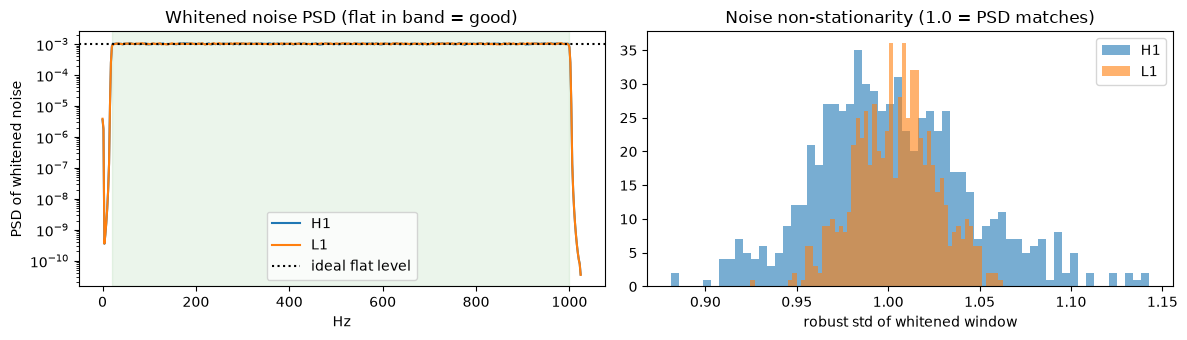

mean std of clean noise windows (should be ~1): [1.0034623 1.0047585]


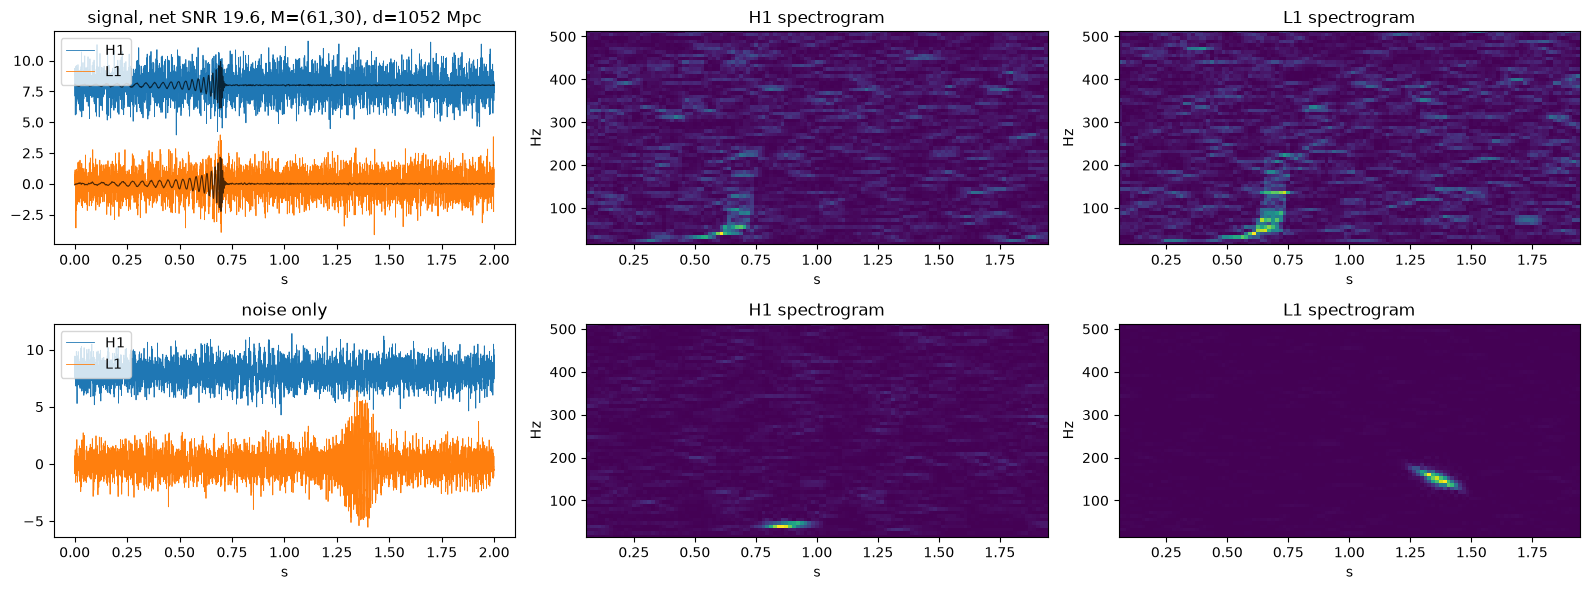

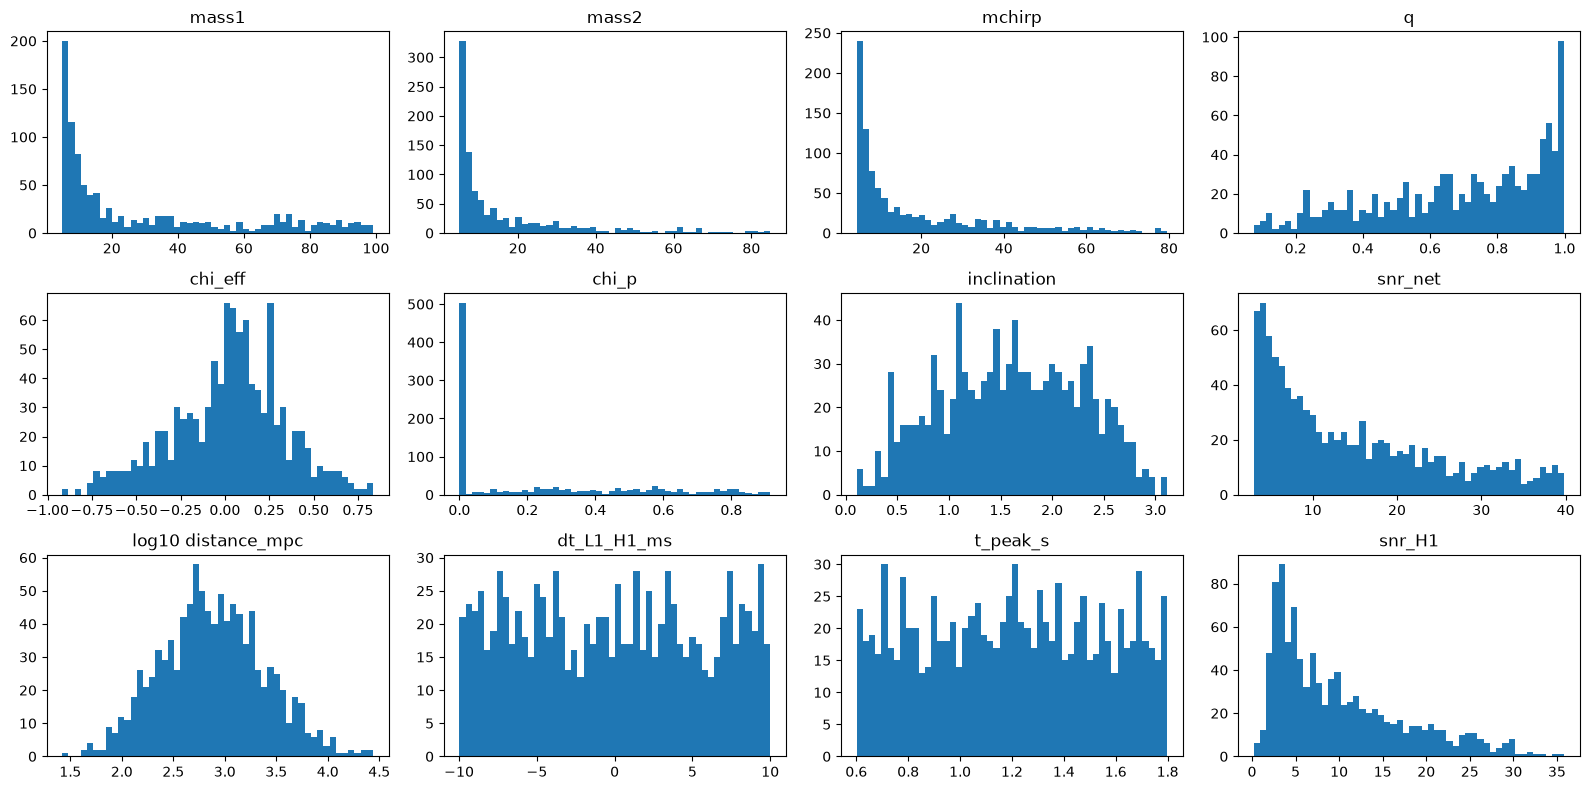

glitch rate  noise: 0.306   signal: 0.307   (should match)
glitch types: {'chirping_whistle': 167, 'scattered_light': 154, 'sine_gaussian': 152, 'blip': 140} | coincident-GPS fraction: 0.30


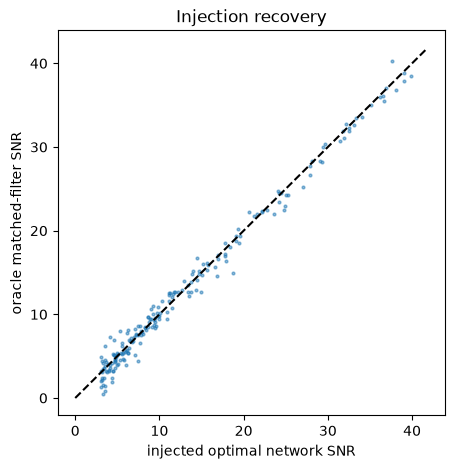

recovered - injected: mean=-0.137  std=1.084   (ideal: 0 and 1)


In [13]:
CFG.update(synthetic_noise=True, out_dir="gw_smoke", cache_dir="noise_cache_smoke")
set_preset("smoke")
metas = build_all()

qc_noise_whitening()
qc_examples("val", snr_target=20)
qc_parameters("train")
qc_injection_recovery("val")

## Step B — build the real dataset

Needs internet access to `gwosc.org`. Rough cost on **one CPU core** in my tests: ≈5.5 ms per example and ≈65 ms per waveform; the waveform bank parallelises across cores
(it uses up to 8). That works out to very roughly 30–40 min for `medium` and ~2 h for `large`, plus the GWOSC download (several GB).
Disk: ≈3.3 GB per 100 k training examples in float32 (set `CFG["store_dtype"]="float16"` to halve it). The build is *resumable at epoch level*: downloaded/processed noise epochs are cached in `cache_dir`.

More noise epochs = more noise diversity: raise `epochs=(train, val, test)` in the preset if you scale `n_train` up.

In [14]:
CFG.update(synthetic_noise=False, out_dir="gw_bbh_dataset_v2", cache_dir="noise_cache", raw_dir="raw_noise")
set_preset("medium")          # "medium" (100k train) or "large" (400k train)
# CFG["n_train"] = 250_000    # optional overrides must come AFTER set_preset
metas = build_all()

epoch 2: GPS ~1249519448
  ep2 H1 GPS 1249517568  good=100.0%  -> (16337, 64, 64)
  ep2 L1 GPS 1249517568  good=100.0%  -> (16337, 64, 64)
epoch 3: GPS ~1267168022
  ep3 H1 GPS 1267167232  good=100.0%  -> (16337, 64, 64)
  ep3 L1 GPS 1267167232  good=100.0%  -> (16337, 64, 64)
epoch 4: GPS ~1260377453
  ep4 H1 GPS 1260376064  good=99.0%  -> (16150, 64, 64)
  ep4 L1 GPS 1260376064  good=100.0%  -> (16337, 64, 64)
epoch 5: GPS ~1268674648
  ep5 H1 GPS 1268674560  good=100.0%  -> (16337, 64, 64)
  ep5 L1 GPS 1268674560  good=100.0%  -> (16337, 64, 64)
epoch 6: GPS ~1259956587
  ep6 H1 GPS 1259954176  good=100.0%  -> (16337, 64, 64)
  ep6 L1 GPS 1259954176  good=100.0%  -> (16337, 64, 64)
epoch 7: GPS ~1253797755
  ep7 H1 GPS 1253793792  good=100.0%  -> (16337, 64, 64)
  ep7 L1 GPS 1253793792  good=100.0%  -> (16337, 64, 64)
epoch 8: GPS ~1252101501
  ep8 H1 GPS 1252098048  good=100.0%  -> (16337, 64, 64)
  ep8 L1 GPS 1252098048  good=100.0%  -> (16337, 64, 64)
epoch 9: GPS ~1246836176
  e

train: 100%|██████████| 200/200 [01:18<00:00,  2.55it/s]


  train: X(100000, 2, 4096)  signals=50000  noise=50000  -> gw_bbh_dataset_v2/train.h5


val: 100%|██████████| 20/20 [00:07<00:00,  2.52it/s]


  val: X(10000, 2, 4096)  signals=5000  noise=5000  -> gw_bbh_dataset_v2/val.h5


...

  test: X(10000, 2, 4096)  signals=5000  noise=5000  -> gw_bbh_dataset_v2/test.h5


bench: 100%|██████████| 18/18 [00:09<00:00,  1.80it/s]


  bench: X(9000, 2, 4096)  signals=9000  noise=0  -> gw_bbh_dataset_v2/bench.h5


far: 100%|██████████| 100/100 [00:23<00:00,  4.20it/s]


  far: X(50000, 2, 4096)  signals=0  noise=50000  -> gw_bbh_dataset_v2/far.h5


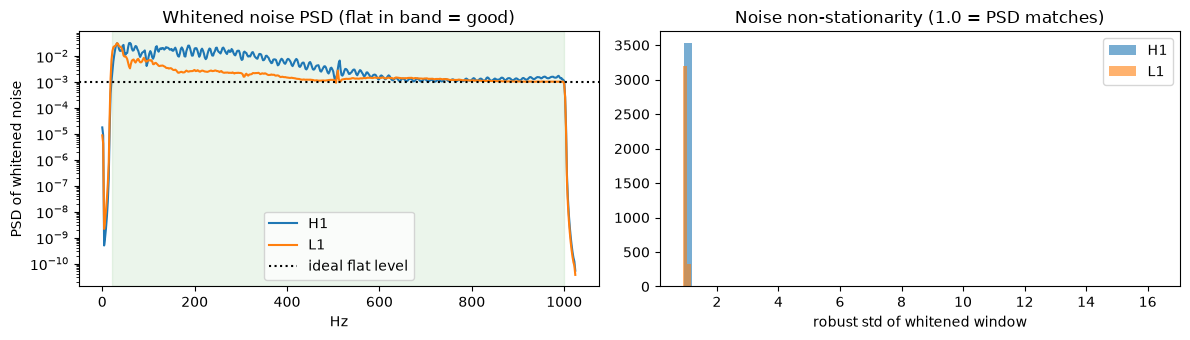

mean std of clean noise windows (should be ~1): [1.0670379 1.0327933]


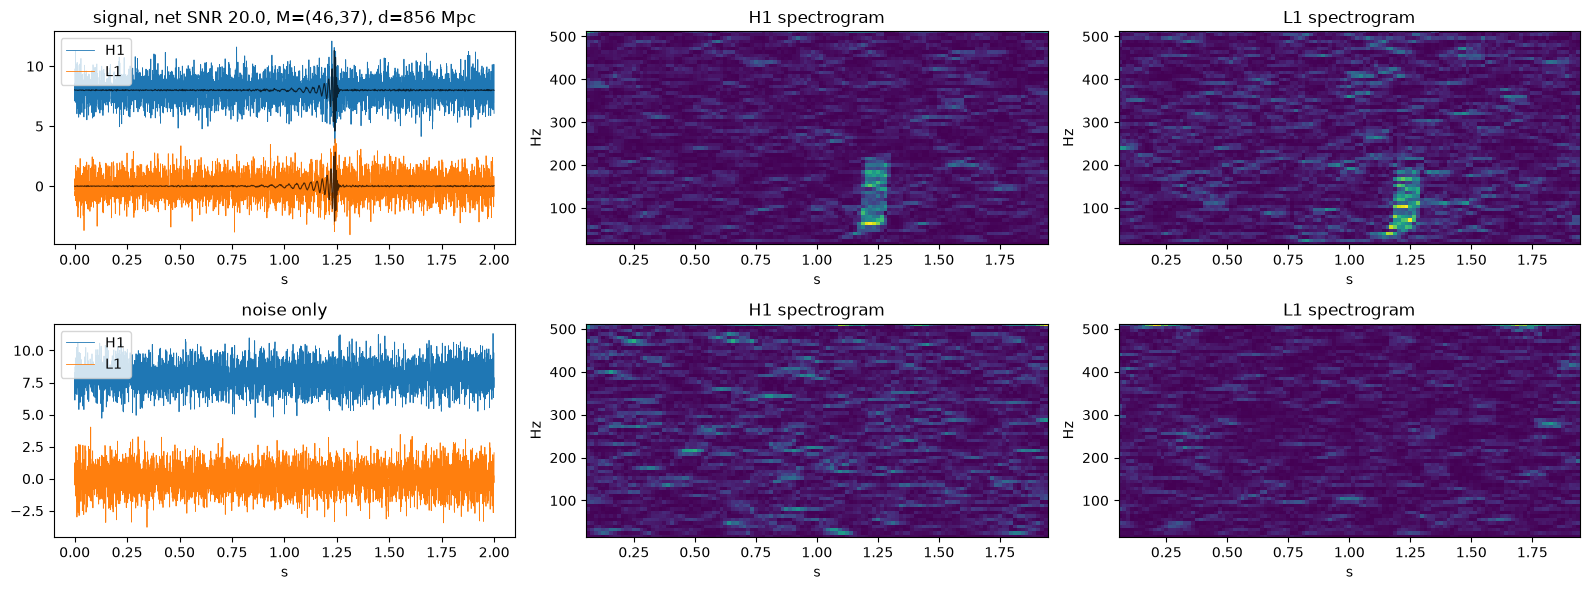

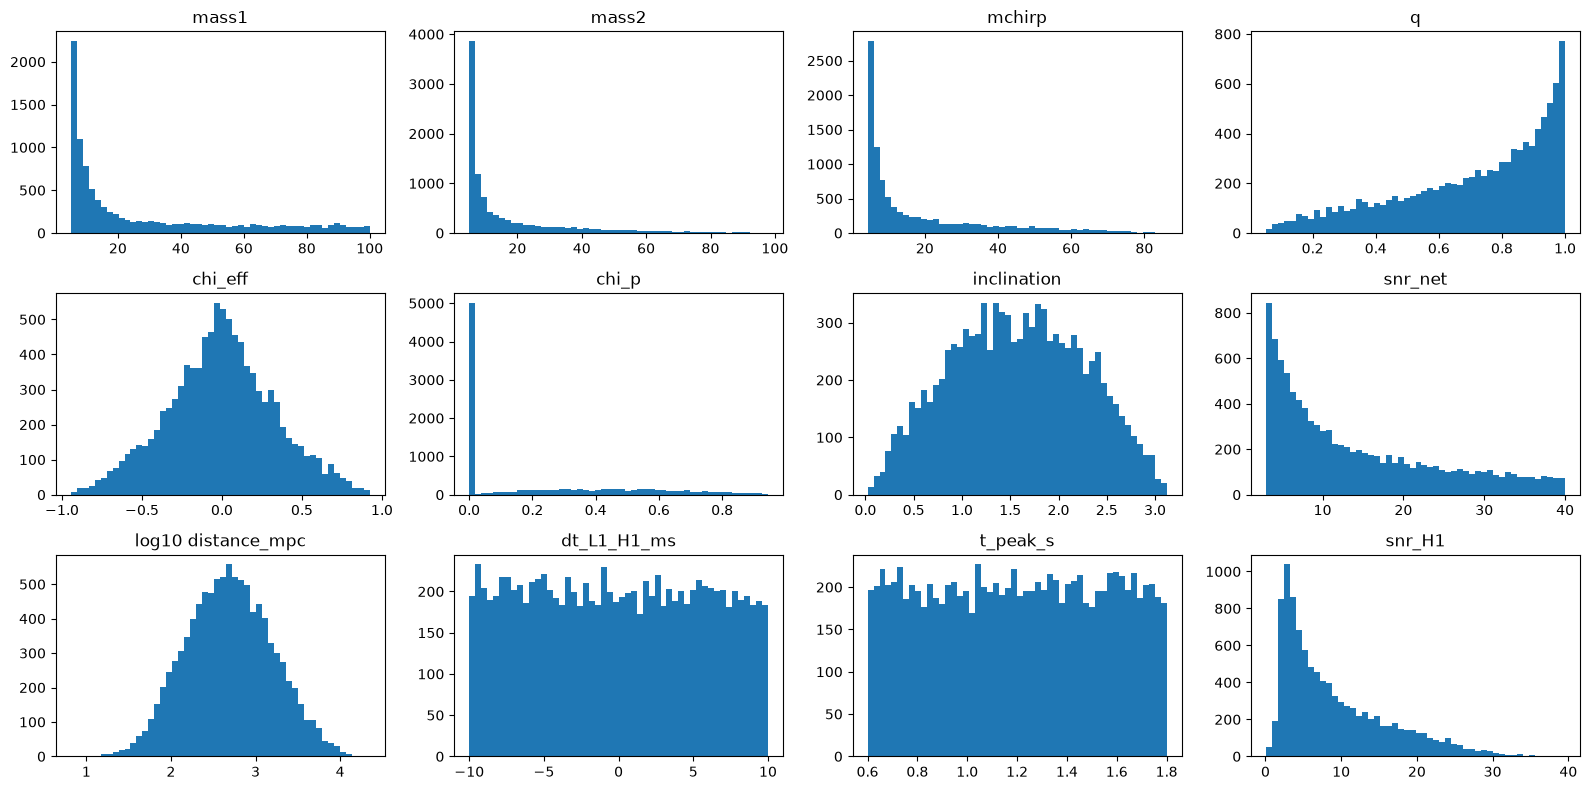

glitch rate  noise: 0.305   signal: 0.293   (should match)
glitch types: {'sine_gaussian': 1560, 'blip': 1513, 'scattered_light': 1482, 'chirping_whistle': 1424} | coincident-GPS fraction: 0.30


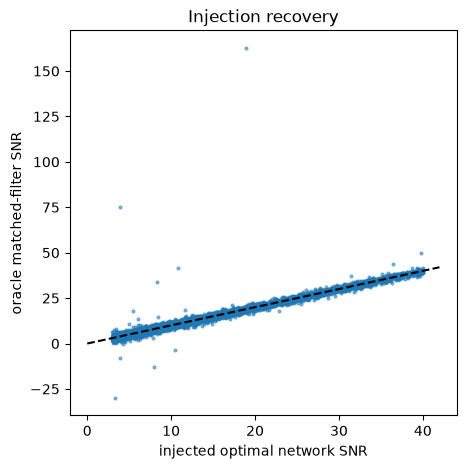

recovered - injected: mean=+0.008  std=2.664   (ideal: 0 and 1)


In [15]:
qc_noise_whitening()
qc_examples("val", snr_target=20)
qc_parameters("train")
qc_injection_recovery("val")

## 12. Loading the data for training

`GWH5Dataset` is a plain map-style dataset (works with `torch.utils.data.DataLoader`). Shapes: `X (N, 2, 4096)` float32, `y (N,)`.
For `medium`, `in_memory=True` is the fast option (≈3.3 GB). For `large`, keep it on disk (`in_memory=False`) with several `num_workers`.

In [16]:
# ---------------- reading the dataset for training ----------------
class GWH5Dataset:
    """Map-style dataset (works directly with torch.utils.data.DataLoader; default collate turns arrays into tensors).
    in_memory=True loads everything into RAM (fast; fine for 'medium'). For 'large', keep in_memory=False and use
    num_workers>0 + a sampler that shuffles in contiguous blocks, or train from several chunks."""
    def __init__(self, path, in_memory=True, use_meta=False, dtype=np.float32):
        self.path, self.dtype, self._f = path, dtype, None
        with h5py.File(path, "r") as f:
            self.y = f["y"][:].astype(np.float32)
            self.X = f["X"][:] if in_memory else None
        self.n = len(self.y)
    def __len__(self): return self.n
    def __getitem__(self, i):
        if self.X is not None:
            x = self.X[i]
        else:
            if self._f is None: self._f = h5py.File(self.path, "r")
            x = self._f["X"][i]
        return np.asarray(x, dtype=self.dtype), self.y[i]

In [17]:
train_ds = GWH5Dataset(os.path.join(CFG["out_dir"], "train.h5"), in_memory=True)
x, y = train_ds[0]
print(len(train_ds), x.shape, x.dtype, y)

# from torch.utils.data import DataLoader
# loader = DataLoader(train_ds, batch_size=256, shuffle=True, num_workers=2, pin_memory=True)

100000 (2, 4096) float32 0.0


## 13. Files written to `out_dir`

| File | Content |
|---|---|
| `{split}.h5` | `X (N,2,4096)`, `y (N,)`, and `S` (clean whitened signal) for val/test/bench |
| `{split}_meta.csv` | one row per example, aligned with `X` (masses, spins, sky, SNR per detector, distance, noise epoch/GPS, glitch info, noise-quality stats…) |
| `psd_table.h5` | per-block PSDs; index with `epoch_*`, `blk_*` from the metadata (needed for the matched-filtering baseline) |
| `dataset_card.json` | the exact configuration used |

## 14. Notes and caveats

- **Masses are detector-frame**, and `distance_mpc` is the luminosity distance implied by the chosen SNR, sky position, inclination and the local PSD — not a cosmological population draw.
- The labelled SNR is the **optimal** SNR; the SNR a matched filter actually measures fluctuates around it by ±1 (that is what `qc_injection_recovery` shows).
- Whitening uses a PSD from the same 64 s block as the data, so slow non-stationarity inside a block remains in the data (std slightly ≠ 1) — useful for a robustness study, and recorded in `std_*` / `robust_std_*`.
- Only catalogued events are vetoed; uncatalogued marginal candidates in the noise are possible but rare.
- Waveform approximant is a choice, not ground truth: `IMRPhenomPv2` has no higher modes. For a higher-fidelity test set, regenerate `test`/`bench` with `APPROXIMANT = "IMRPhenomXPHM"` (slower).

## 15. Suggested next steps

1. Train a 2-channel 1D CNN on `train.h5`; early-stop on `val.h5`.
2. Matched-filter baseline: build a template bank from the `train_meta.csv` parameters, whiten templates with the PSDs in `psd_table.h5`, and compare.
3. Evaluate on `bench` (efficiency vs SNR) with the detection threshold set by the false-positive rate measured on `far`.

In [18]:
import glob, h5py, numpy as np

path = sorted(glob.glob("raw_noise/*H1*.hdf5"))[0]
print(path)
with h5py.File(path, "r") as f:
    x = f["strain/Strain"][:]
    dur = int(f["meta/Duration"][()])
    print("samples:", len(x), "| duration:", dur, "| finite fraction:", np.isfinite(x).mean())
    print("quality keys:", list(f["quality"].keys()), list(f["quality/simple"].keys()))

    dq = f["quality/simple/DQmask"][:]
    names = [n.decode() if isinstance(n, bytes) else str(n) for n in f["quality/simple/DQShortnames"][()]]
    print("DQmask length:", len(dq))
    for i, n in enumerate(names):
        print(f"  DQ bit {i:2d} {n:20s} set in {((dq >> i) & 1).mean():6.1%} of seconds")

    if "quality/injections/Injmask" in f:
        im = f["quality/injections/Injmask"][:]
        inames = [n.decode() if isinstance(n, bytes) else str(n) for n in f["quality/injections/InjShortnames"][()]]
        for i, n in enumerate(inames):
            print(f"  INJ bit {i:2d} {n:24s} set in {((im >> i) & 1).mean():6.1%} of seconds")

raw_noise/H-H1_GWOSC_O3a_4KHZ_R1-1244024832-4096.hdf5
samples: 16777216 | duration: 4096 | finite fraction: 1.0
quality keys: ['detail', 'injections', 'simple'] ['DQDescriptions', 'DQShortnames', 'DQmask', 'GWOSCmeta']
DQmask length: 4096
  DQ bit  0 DATA                 set in 100.0% of seconds
  DQ bit  1 CBC_CAT1             set in 100.0% of seconds
  DQ bit  2 CBC_CAT2             set in 100.0% of seconds
  DQ bit  3 CBC_CAT3             set in 100.0% of seconds
  DQ bit  4 BURST_CAT1           set in 100.0% of seconds
  DQ bit  5 BURST_CAT2           set in  98.5% of seconds
  DQ bit  6 BURST_CAT3           set in  98.5% of seconds
  INJ bit  0 NO_CBC_HW_INJ            set in 100.0% of seconds
  INJ bit  1 NO_BURST_HW_INJ          set in 100.0% of seconds
  INJ bit  2 NO_DETCHAR_HW_INJ        set in 100.0% of seconds
  INJ bit  3 NO_CW_HW_INJ             set in   0.0% of seconds
  INJ bit  4 NO_STOCH_HW_INJ          set in 100.0% of seconds
